# Plants Disease Classification Model

## Importing Requirements:

In [2]:
import torch
from torch import nn
from torch.utils.data import Dataset , DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision import models
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
import numpy as np
import os
from tqdm import tqdm
from addict import Dict
import random
from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt
import os
import logging
%matplotlib inline


## Functions:

In [2]:
def seed_everything(seed:int=42) -> None:
    random.seed(seed)
    os.environ['PYTHONASSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True


###Model selection:
def get_optimizer(model:torch.nn.Module, name:str="SGD", parameters:dict={}) -> torch.optim.Optimizer:
    optimizers = {
        "SGD": torch.optim.SGD,
        "AdamW": torch.optim.AdamW,
        "Adam": torch.optim.Adam,
        "RMSprop": torch.optim.RMSprop,
    }
    instance = optimizers.get(name, "SGD")     
    optimizer = instance(model.parameters(), **parameters)
    return optimizer

###Scheduler selection:
def get_scheduler(optimizer:torch.optim.Optimizer, name:str, parameters:dict):
    schedulers = {
        "ReduceLROnPlateau": torch.optim.lr_scheduler.ReduceLROnPlateau,
        "LambdaLR" : torch.optim.lr_scheduler.LambdaLR,
        "StepLR" : torch.optim.lr_scheduler.StepLR,
        "ExponentialLR": torch.optim.lr_scheduler.ExponentialLR,
        "Multiplicativelr": torch.optim.lr_scheduler.MultiplicativeLR,
        "MultistepsLR": torch.optim.lr_scheduler.MultiStepLR
    }
    instance = schedulers[name]
    scheduler = instance(optimizer, **parameters)

    return scheduler

###Accuracy Score Checker
def accuracy_score(predictions:torch.Tensor, targets:torch.Tensor) ->torch.Tensor:
    amount = ( predictions == targets ).sum() 
    accuracy = amount/ targets.size(0)
    return accuracy

###Hiding the spines of the Graph
def hide_spines(ax, spines = ["top","right","left","bottom"]):
    for spine in spines:
        ax.spines[spine].set_visible(False)

def plot_images(rows, cols, indexes, class_=0):
    min_index = min(indexes)
    max_index = max(indexes)
    fig = plt.figure(figsize=(3*cols, 3*rows))
    for i in range(*indexes):
        item = train_dataset[i]
        image = item.image
        label = item.label

        if label == class_:
            ax = fig.add_subplot(rows, cols, (i - min_index)+1)
            ax.imshow(image.permute(1, 2, 0))
            ax.xaxis.set_visible(False)
            ax.yaxis.set_visible(False)

    fig.text(s=f"{train_dataset.labels[class_]} leaves", x=0.125, y=0.9, fontweight="bold", fontfamily="serif", fontsize=20)
    fig.show()



###Logging configuration
from logging_config import get_logger


### Configurations

In [3]:
config = Dict({
    "train_path": "D:\projects\Plants Disease Classification\Train\Train",
    "test_path": "D:\projects\Plants Disease Classification\Test\Test",
    "validation_path": "D:\projects\Plants Disease Classification\Validation\Validation"
})

train_config = Dict({
    "device": torch.device("cpu"),
    "epochs": 5,
    "seed": 2021,
    "image_shape": (128, 128),
    "image_channels": 3,
    "num_workers": 0,
    "batch_size": 8, 

    "augmentations": A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        #A.Blur(p=1),
        ToTensorV2(),
    ]),
    "optimizer": {
        "type": "AdamW",
        "parameters": {
            "lr": 0.001,
            "weight_decay": 0.01,
        }
    },
    
    "scheduler": {
        "type": "ReduceLROnPlateau",
        "parameters": {
            "patience": 2,
            "mode": "min",
            "factor": 0.1,
        }
    }
})


seed_everything(train_config.seed)

## Dataset

In [4]:
class PlantDiseaseDataset(Dataset):
    def __init__(self, path, augmentations=None, image_shape=(128, 128), channels="RGB"):
        self.__images_labels = []
        self.image_shape = image_shape
        self.channels = channels
        self.augmentations = augmentations
        
        if os.path.exists(path):
                    self.labels = os.listdir(path)
                    for label in self.labels:
                        label_path = os.path.join(path, label)
                        if os.path.isdir(label_path):
                            files = os.listdir(label_path)
                            for file in files:
                                if file.endswith("jpg") or file.endswith("png"):
                                    image_path = os.path.join(label_path, file)
                                    self.__images_labels.append((image_path, label))
                                else:
                                    pass
                        else:
                            pass
                        
        else:
             pass      
        
        
    def _load(self, path, channels="RGB"):
        width, height = self.image_shape
        loader = A.Compose([
            A.Resize(width=width, height=height),
            ToTensorV2(),
        ])
        
        image_array = np.array(Image.open(path).convert(channels))
        return loader(image=image_array)["image"]
    
    def __len__(self):
        return len(self.__images_labels)
    
    def __getitem__(self, index):
        path, label = self.__images_labels[index]
        image = self._load(path)
        
        if self.augmentations is not None:
            image = image.permute(1, 2, 0).numpy()
            image = self.augmentations(image=image)["image"]
            
        label = self.labels.index(label)
        
        return Dict({
            "image": image,
            "label": label,
        })
    
    
def collate_fn(batch):
    all_images, all_labels = [], []
    for item in batch:
        image = item.image
        label = item.label
        
        all_images.append(item.image.tolist())
        all_labels.append(label)
        
    return { 
        "images": torch.tensor(all_images),
        "labels": torch.tensor(all_labels, dtype=torch.int8)
    }
        

## EDA

In [5]:
train_dataset = PlantDiseaseDataset(path=config.train_path, 
                                    image_shape=train_config.image_shape, 
                                    channels=train_config.image_channels)

C:\Users\Jc\AppData\Local\Temp\ipykernel_11620\1993530757.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=train_dataset.labels, y=amount, palette=palette,  ec="#000", linewidth=1.5, zorder=2, ax=ax)


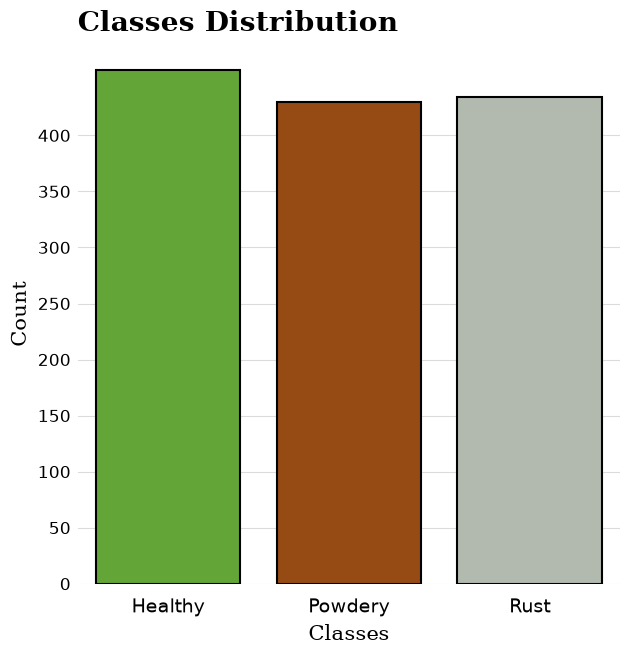

In [6]:
label_pathes = [os.path.join(config.train_path, label) for label in train_dataset.labels]
label_files = [os.listdir(path) for path in label_pathes]
amount = [len(files) for files in label_files]

palette = sns.color_palette(["#5FB924", "#AB4800", "#B2BBAC"])
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot()
ax.grid(color="lightgrey", axis="both", alpha=0.8, zorder=0)
sns.barplot(x=train_dataset.labels, y=amount, palette=palette,  ec="#000", linewidth=1.5, zorder=2, ax=ax)
ax.xaxis.set_tick_params(labelsize=14, size=0, pad=10)
ax.yaxis.set_tick_params(labelsize=12, size=0, pad=5)
ax.set_yticks(list(range(0, 450, 50)))
ax.set_title(f"Classes Distribution", fontsize=20, fontweight="bold", fontfamily="serif", loc="left", y=1.01)
ax.set_xlabel("Classes", fontsize=15, fontfamily="serif", labelpad=5)
ax.set_ylabel("Count", fontsize=15, fontfamily="serif", labelpad=5)
hide_spines(ax)
plt.show()

C:\Users\Jc\AppData\Local\Temp\ipykernel_11620\2590794903.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


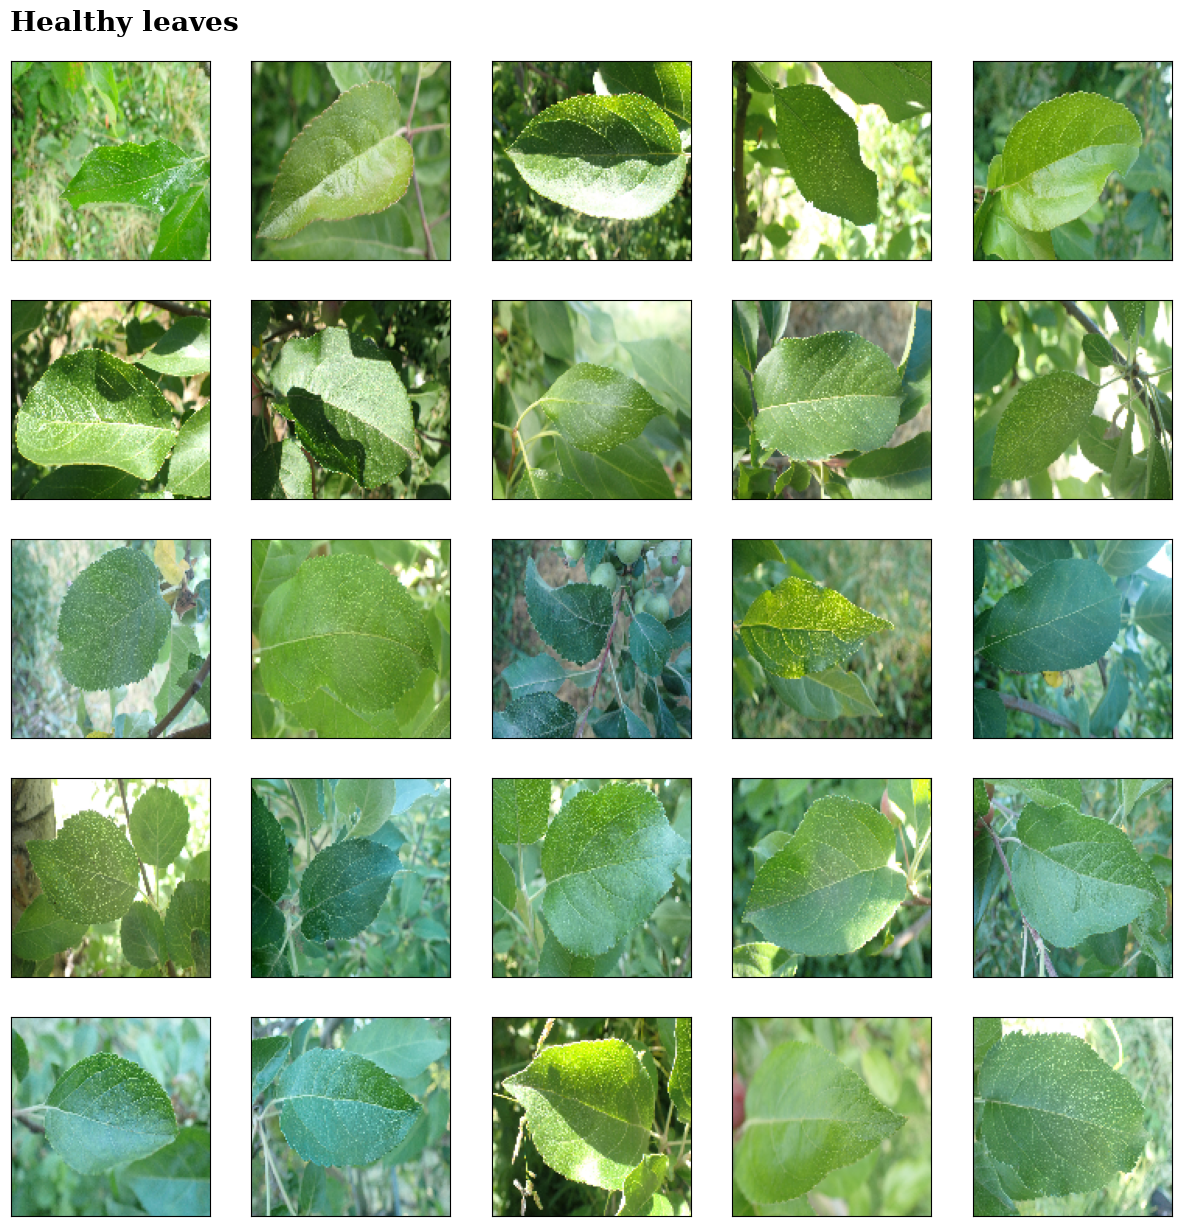

In [7]:
plot_images(rows=5, cols=5, indexes=(0, 25), class_=0)

In [8]:
plot_images(rows=5, cols=5, indexes=(0, 25), class_=1)

C:\Users\Jc\AppData\Local\Temp\ipykernel_11620\2590794903.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Figure size 1500x1500 with 0 Axes>

In [9]:
plot_images(rows=5, cols=5, indexes=(0,25), class_=2)

C:\Users\Jc\AppData\Local\Temp\ipykernel_11620\2590794903.py:65: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


<Figure size 1500x1500 with 0 Axes>

### Prepare the Dataset and the dataloader

In [10]:
train_dataset = PlantDiseaseDataset(path=config.train_path, 
                                    augmentations=train_config.augmentations,
                                    image_shape=train_config.image_shape, 
                                    channels=train_config.image_channels)

validation_dataset = PlantDiseaseDataset(path=config.validation_path, 
                                         augmentations=train_config.augmentations,
                                         image_shape=train_config.image_shape, 
                                         channels=train_config.image_channels)

test_dataset = PlantDiseaseDataset(path=config.test_path, 
                                   augmentations=train_config.augmentations,
                                   image_shape=train_config.image_shape, 
                                   channels=train_config.image_channels)

### Dataloader to load data to NN

In [11]:
train_loader = DataLoader(dataset=train_dataset, 
                          batch_size=train_config.batch_size, 
                          num_workers=train_config.num_workers, 
                          pin_memory=True, 
                          shuffle=True, 
                          collate_fn=collate_fn)

validation_loader = DataLoader(dataset=validation_dataset, 
                               batch_size=train_config.batch_size*2, 
                               num_workers=train_config.num_workers, 
                               pin_memory=True, 
                               shuffle=False, 
                               collate_fn=collate_fn)

test_loader = DataLoader(dataset=test_dataset, 
                         batch_size=train_config.batch_size*2, 
                         num_workers=train_config.num_workers, 
                         pin_memory=True, 
                         shuffle=False, 
                         collate_fn=collate_fn)

## Modelling 

In [12]:
class PlantDiseaseModel(nn.Module):
    def __init__(self, classes=2):
        super(PlantDiseaseModel, self).__init__()
        self.model = models.resnet34(pretrained=True)
        
        for parameter in self.model.parameters():
            parameter.requires_grad = False
        
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Linear(in_features=in_features, out_features=classes),
            nn.Softmax(dim=1)
        )
        
    def forward(self, image):
        output = self.model(image)
        return output

In [13]:
class Trainer:
    def __init__(self, model, criterion, optimizer,  metric, scheduler=None, logger=None, device="cpu"):
        self.model = model
        self.criterion = criterion
        self.optimizer = optimizer
        self.scheduler = scheduler
        self.logger = logger
        self.device = torch.device(device)
        self.best_validation_loss = float("inf")
        self.metric = metric
        self.history = Dict({})
        
    def __log(self, logs):
        for k, v in logs.items():
            if k not in self.history:
                self.history[k] = []
                
            self.history[k].append(v)
            
    def evaluate(self, loader):
        loss, score, length = 0, 0, len(loader)
            
        self.model.to(self.device)
        with torch.no_grad():
            loop = tqdm(loader, position=0, colour="BLACK", desc=f"Evaluating: ", leave=True)
            for batch in loop:
                if self.device.type != "cpu": torch.cuda.empty_cache()
                self.model.eval()

                images = batch["images"].float().to(self.device)
                labels = batch["labels"].long().to("cpu")

                probabilities = self.model(images).float().to("cpu")
                predictions = torch.argmax(probabilities, dim=1).detach()

                batch_loss = self.criterion(probabilities, labels)
                loss += batch_loss.item()
                
                batch_score = self.metric(predictions, labels).item()
                score += batch_score

            loss /= length
            score /= length
        
        return loss, score
        


    def fit(self, train_loader, validation_loader=None, epochs=10):
        self.model.to(self.device)
        train_length = len(train_loader)
        
        for epoch in range(epochs): 
            epoch_loss, epoch_score = 0, 0
            
            loop = tqdm(train_loader, position=0, colour="BLACK", leave=True, desc=f"Epoch [{epoch+1}/{epochs}]: ")
            for batch in loop:
                if self.device.type != "cpu": torch.cuda.empty_cache()
                self.optimizer.zero_grad()
                self.model.train()
                
                images = batch["images"].float().to(self.device)
                labels = batch["labels"].long().to("cpu")

                probabilities = self.model(images).float().to("cpu")
                predictions = torch.argmax(probabilities, dim=1).detach()
                
                batch_loss = self.criterion(probabilities, labels)
                epoch_loss += batch_loss.item()
                
                batch_score = self.metric(predictions, labels).item()
                epoch_score += batch_score
                
                batch_loss.backward()
                self.optimizer.step()
                
            epoch_loss /= train_length
            epoch_score /= train_length
            
            self.__log({"train_losses": epoch_loss, "train_scores": epoch_score})
            if self.logger is not None: self.logger.info(f"Epoch [{epoch+1}/{epochs}]: Loss: {epoch_loss} | Metric: {epoch_score}")
                
            if validation_loader is not None:
                validation_loss, validation_score = self.evaluate(validation_loader)
                self.__log({"validation_losses": validation_loss, "validation_scores": validation_score})
                if self.logger is not None: self.logger.info(f"Validation Epoch [{epoch+1}/{epochs}]: Loss: {validation_loss} | Metric: {validation_score}")
            


                if self.scheduler is not None:
                    if isinstance(self.scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
                        self.scheduler.step(validation_loss)
                    else:
                        self.scheduler.step()

                    if self.logger is not None:
                        lr = self.optimizer.param_groups[0]["lr"]
                        self.logger.info(f"Epoch [{epoch+1}/{epochs}] Learning Rate: {lr}")

In [ ]:
model = PlantDiseaseModel(classes=len(train_dataset.labels))
criterion = nn.CrossEntropyLoss()
optimizer = get_optimizer(model=model, 
                          name=train_config.optimizer.type, 
                          parameters=train_config.optimizer.parameters)

if "scheduler" in train_config:
    scheduler = get_scheduler(optimizer=optimizer, 
                              name=train_config.scheduler.type, 
                              parameters=train_config.scheduler.parameters)
    
trainer_logger = get_logger("trainer")
trainer = Trainer(model=model, 
                  criterion=criterion,
                  metric=accuracy_score,
                  optimizer=optimizer, 
                  scheduler=scheduler,
                  logger=trainer_logger,
                  device=train_config.device)

d:\projects\Plants Disease Classification\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\projects\Plants Disease Classification\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


## Training the Model

In [ ]:
trainer.fit(train_loader=train_loader, 
            validation_loader=validation_loader, 
            epochs=train_config.epochs)

Epoch [1/5]:   0%|          | 0/166 [00:00<?, ?it/s]

Epoch [1/5]: 100%|██████████| 166/166 [05:41<00:00,  2.06s/it]
2026-11-16 15:19:26 | INFO | trainer | Epoch [1/5]: Loss: 0.889035521142454 | Metric: 0.6927710843373494
Evaluating: 100%|██████████| 4/4 [00:16<00:00,  4.08s/it]
2026-11-16 15:19:43 | INFO | trainer | Validation Epoch [1/5]: Loss: 0.761756643652916 | Metric: 0.8645833283662796
2026-11-16 15:19:43 | INFO | trainer | Epoch [1/5] Learning Rate: 0.001
Epoch [2/5]: 100%|██████████| 166/166 [06:32<00:00,  2.37s/it]
2026-11-16 15:26:15 | INFO | trainer | Epoch [2/5]: Loss: 0.7581509308642652 | Metric: 0.8230421686746988
Evaluating: 100%|██████████| 4/4 [00:18<00:00,  4.68s/it]
2026-11-16 15:26:34 | INFO | trainer | Validation Epoch [2/5]: Loss: 0.7026441246271133 | Metric: 0.8697916716337204
2026-11-16 15:26:34 | INFO | trainer | Epoch [2/5] Learning Rate: 0.001
Epoch [3/5]: 100%|██████████| 166/166 [06:29<00:00,  2.35s/it]
2026-11-16 15:33:04 | INFO | trainer | Epoch [3/5]: Loss: 0.7273094593042351 | Metric: 0.8524096385542169
E

## Visualization of the performance of Model 

C:\Users\Jc\AppData\Local\Temp\ipykernel_10812\3275710503.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


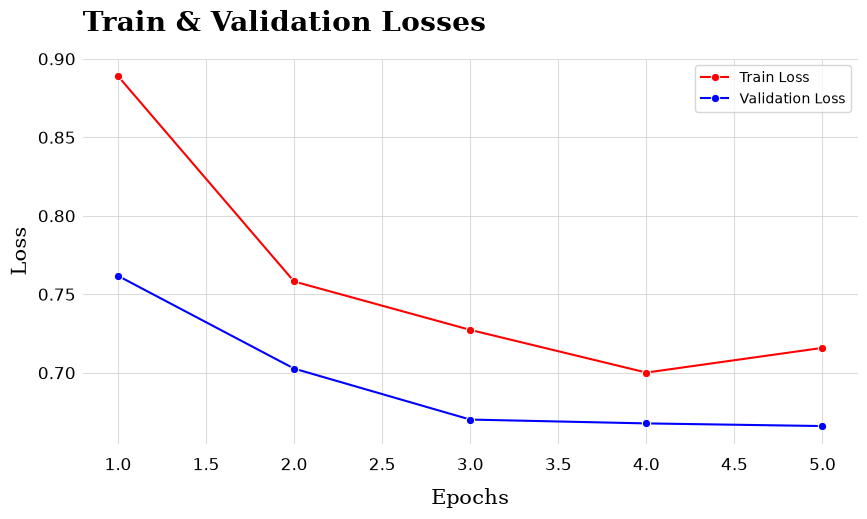

In [ ]:
epochs_ = range(1, train_config.epochs+1)
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot()
ax.grid(color="lightgrey", axis="both", alpha=0.8, zorder=0)
sns.lineplot(x=epochs_, y=trainer.history.train_losses, color="red", marker="o", label="Train Loss", zorder=2, ax=ax)
sns.lineplot(x=epochs_, y=trainer.history.validation_losses, color="blue", marker="o", label="Validation Loss", zorder=2, ax=ax)
ax.set_title("Train & Validation Losses", fontsize=20, fontweight="bold", fontfamily="serif", loc="left", y=1.05)
hide_spines(ax)
ax.xaxis.set_tick_params(labelsize=12, size=0, pad=10)
ax.yaxis.set_tick_params(labelsize=12, size=0, pad=5)
ax.set_xlabel("Epochs", fontsize=15, fontfamily="serif", labelpad=10)
ax.set_ylabel("Loss", fontsize=15, fontfamily="serif", labelpad=5)
ax.legend()
fig.show()

C:\Users\Jc\AppData\Local\Temp\ipykernel_10812\1485051734.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


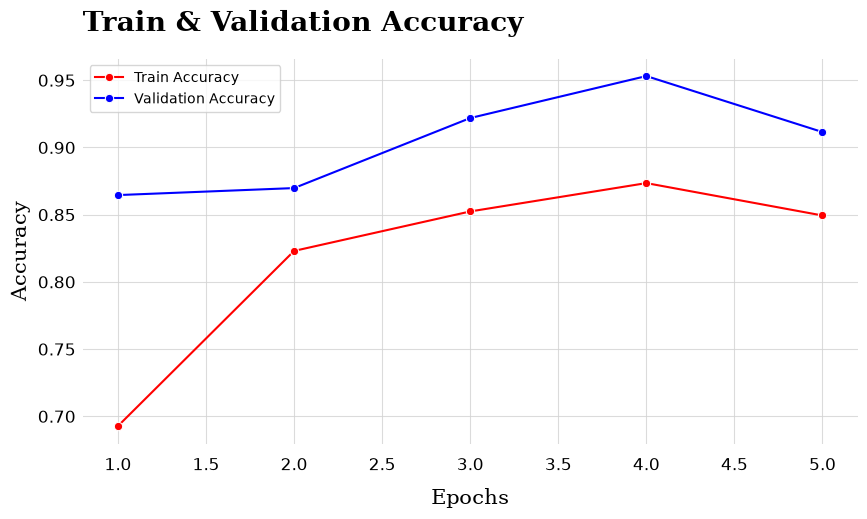

In [ ]:
fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot()
ax.grid(color="lightgrey", axis="both", alpha=0.8, zorder=0)
sns.lineplot(x=epochs_, y=trainer.history.train_scores, color="red", marker="o", label="Train Accuracy", zorder=2, ax=ax)
sns.lineplot(x=epochs_, y=trainer.history.validation_scores, color="blue", marker="o", label="Validation Accuracy", zorder=2, ax=ax)
ax.set_title("Train & Validation Accuracy", fontsize=20, fontweight="bold", fontfamily="serif", loc="left", y=1.05)
hide_spines(ax)
ax.xaxis.set_tick_params(labelsize=12, size=0, pad=10)
ax.yaxis.set_tick_params(labelsize=12, size=0, pad=5)
ax.set_xlabel("Epochs", fontsize=15, fontfamily="serif", labelpad=10)
ax.set_ylabel("Accuracy", fontsize=15, fontfamily="serif", labelpad=5)
ax.legend()
fig.show()

## Testing the Model performance

In [ ]:
validation_scores = trainer.history.validation_scores
best_index = int(np.argmax(validation_scores))

print(f"Highest validation accuracy: {validation_scores[best_index]:.2%}")
print(f"Reached at epoch: {best_index + 1}")

Highest validation accuracy: 95.31%
Reached at epoch: 4


In [ ]:
model.eval()

PlantDiseaseModel(
  (model): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, t

In [ ]:
test_loader = DataLoader(
    test_dataset,
    batch_size=train_config.batch_size,
    shuffle=False,
    num_workers=0
)

In [ ]:
model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for images, labels in test_loader:

        device = train_config.device
        model.to(device)
        model.eval()

        all_predictions = []
        all_targets = []

        with torch.no_grad():
            for batch in test_loader:
                images = batch["image"].float().to(device)
                labels = batch["label"].long()

                predictions = model(images).argmax(dim=1)

                all_predictions.extend(predictions.cpu().tolist())
                all_targets.extend(labels.cpu().tolist())
        model.eval()
        device = train_config.device
        model.to(device).eval()

        all_predictions = []
        all_targets = []

        with torch.no_grad():
            for batch in test_loader:
                images = batch["image"].float().to(device)
                labels = batch["label"].long()

                outputs = model(images)
                predictions = outputs.argmax(dim=1)

                all_predictions.extend(predictions.cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(labels.cpu().numpy())

In [ ]:
import sklearn


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    all_targets,
    all_predictions
)

print("Test Accuracy:", accuracy)


Test Accuracy: 0.9038461538461539


#### Test accuracy is 0.9038461538461539

## Exporting the Model in onnx format

In [ ]:
import torch

model_path = "plant_disease_model.pth"

torch.save(
    {
        "model_state_dict": {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        "class_names": train_dataset.labels,
        "image_shape": train_config.image_shape,
        "image_channels": train_config.image_channels,
    },
    model_path,
)

print(f"Model exported to: {model_path}")

Model exported to: plant_disease_model.pth


In [ ]:
model.eval()

height, width = train_config.image_shape
dummy_input = torch.randn(
    1, train_config.image_channels, height, width
)

torch.onnx.export(
    model.cpu(),
    dummy_input,
    "plant_disease_model.onnx",
    input_names=["image"],
    output_names=["probabilities"],
    dynamic_axes={
        "image": {0: "batch_size"},
        "probabilities": {0: "batch_size"},
    },
    opset_version=17,
    dynamo=False,
)

print("Exported plant_disease_model.onnx")

Exported plant_disease_model.onnx


In [7]:
import onnxruntime as ort
import numpy as np
from PIL import Image
import os

model_path = "plant_disease_model.onnx"
image_path = r"D:\projects\Plants Disease Classification\Test\Test\Powdery\9e0ba1619bdf4943.jpg"

# Reuse the class order saved with the PyTorch checkpoint.
checkpoint = torch.load("plant_disease_model.pth", map_location="cpu")
class_names = checkpoint["class_names"]
height, width = checkpoint["image_shape"]

# Load the ONNX model.
session = ort.InferenceSession(
    model_path,
    providers=["CPUExecutionProvider"]
)

# Match the notebook's preprocessing: RGB, resized to 128x128,
# converted to a float tensor in NCHW layout.
image = Image.open("D:\projects\Plants Disease Classification\Test\Test\Powdery\9e0ba1619bdf4943.jpg").convert("RGB").resize((128,128))
image = np.asarray(image, dtype=np.float32)
image = np.transpose(image, (2, 0, 1))[None, ...]

# Run prediction and display the top class and confidence.
input_name = session.get_inputs()[0].name
output = session.run(None, {input_name: image})[0]
scores = output[0]
predicted_index = int(np.argmax(scores))

print("Image:", os.path.basename(image_path))
print("Prediction:", class_names[predicted_index])
print(f"Confidence: {scores[predicted_index]:.2%}")

Image: 9e0ba1619bdf4943.jpg
Prediction: Powdery
Confidence: 97.49%
